# Simpsons opt experiment data processing and report

In [2]:
import pathlib
import typing

import numpy as np
import pandas as pd
import spock
import json
import matplotlib.pyplot as plt
import seaborn as sns

import yaml

In [3]:
sns.set_theme()
plt.rcParams['figure.figsize'] = (10.0, 8.0)

In [4]:
PATH_EXPERIMENT = "/beegfs/ws/0/s4610340-isml/simpsons/experiments/25_simpsons_opt_tl_vgg16_split_cv_AdamW"
SEED_ATTR = "train_test_split_algorithm_seed"

## Read the data

In [10]:
class ExperimentResult(typing.NamedTuple):
    config: dict[str, typing.Any]
    result: dict[str, typing.Any]

def read_opt_results(path_experiment: pathlib.Path) -> dict[str, ExperimentResult]:
    path_results = path_experiment / "results"
    d = {}
    for path_result in path_results.glob("*"):
        path_spock_config = next(path_result.glob("*.spock.cfg.yaml"))
        uid = path_result.stem
        with open(path_spock_config, "r") as config_file:
            config = yaml.load(config_file)
        try:
            result = json.loads(next(path_result.glob("result-*.json")).read_text())
        except StopIteration:
            print("Error in train, results do not exist for: ", path_result)
            continue
        d[uid] = ExperimentResult(config=config["ExperimentConfig"], result=result)
    return d

In [11]:
opt_results = read_opt_results(pathlib.Path(PATH_EXPERIMENT))
print("Observations count", len(opt_results.values()))

/tmp/ipykernel_1391648/3090002764.py:12: YAMLLoadWarning: calling yaml.load() without Loader=... is deprecated, as the default Loader is unsafe. Please read https://msg.pyyaml.org/load for full details.
  config = yaml.load(config_file)


Error in train, results do not exist for:  /beegfs/ws/0/s4610340-isml/simpsons/experiments/25_simpsons_opt_tl_vgg16_split_cv_AdamW/results/8034c30d-08b9-4adc-a4e0-c13f66cbf6b3
Error in train, results do not exist for:  /beegfs/ws/0/s4610340-isml/simpsons/experiments/25_simpsons_opt_tl_vgg16_split_cv_AdamW/results/6de5d6f8-0d51-4f2a-b39d-cdc00a3b19dd
Error in train, results do not exist for:  /beegfs/ws/0/s4610340-isml/simpsons/experiments/25_simpsons_opt_tl_vgg16_split_cv_AdamW/results/00dcabff-b16c-48d2-90e6-b905c39f0314
Error in train, results do not exist for:  /beegfs/ws/0/s4610340-isml/simpsons/experiments/25_simpsons_opt_tl_vgg16_split_cv_AdamW/results/6bee3912-ad13-4956-a94c-4dbf4ffca390
Error in train, results do not exist for:  /beegfs/ws/0/s4610340-isml/simpsons/experiments/25_simpsons_opt_tl_vgg16_split_cv_AdamW/results/20aebd53-2a97-4cbe-8fbd-01d765782c87
Error in train, results do not exist for:  /beegfs/ws/0/s4610340-isml/simpsons/experiments/25_simpsons_opt_tl_vgg16_spli

## Process the data

In [12]:
def get_metric_values(
        opt_results: dict[str, ExperimentResult],
        seed_attr: str
) -> pd.DataFrame:
    seeds = []
    metric_values = []
    for experiment_uid, opt_result in opt_results.items():
        seeds.append(opt_result.config[seed_attr])
        metric_values.append(opt_result.result["result_data"]["target_metric_value"])
    s = pd.DataFrame(data=metric_values, index=seeds, columns=[opt_result.config["target_metric"]])
    s.index.name = SEED_ATTR
    return s

In [13]:
PATH_DATA_PROCESSED = pathlib.Path(PATH_EXPERIMENT) / "data" / "processed"
PATH_DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
PATH_DATA_PROCESSED

PosixPath('/beegfs/ws/0/s4610340-isml/simpsons/experiments/25_simpsons_opt_tl_vgg16_split_cv_AdamW/data/processed')

In [14]:
PATH_METRIC_VALUES = PATH_DATA_PROCESSED / "metric_values.csv"
if PATH_METRIC_VALUES.exists():
    metric_values = pd.read_csv(PATH_METRIC_VALUES, index_col=0)
else:
    metric_values = get_metric_values(opt_results, SEED_ATTR)
    metric_values.to_csv(PATH_METRIC_VALUES, index=True)

metric_values

,error_rate
train_test_split_algorithm_seed,
8176,0.081154
5470,0.083124
9057,0.090469
532,0.084557
9418,0.091841
...,...
8725,0.086827
1018,0.081751
6289,0.086350


## Plot metric distribution

[Text(0.5, 1.0, 'Empirical distribution of error rate.\nDataset: simpsons; \nVarying train_test_split_algorithm_seed;\n Observations count: 957 \n Train-test-split algorithm: cross-validation')]

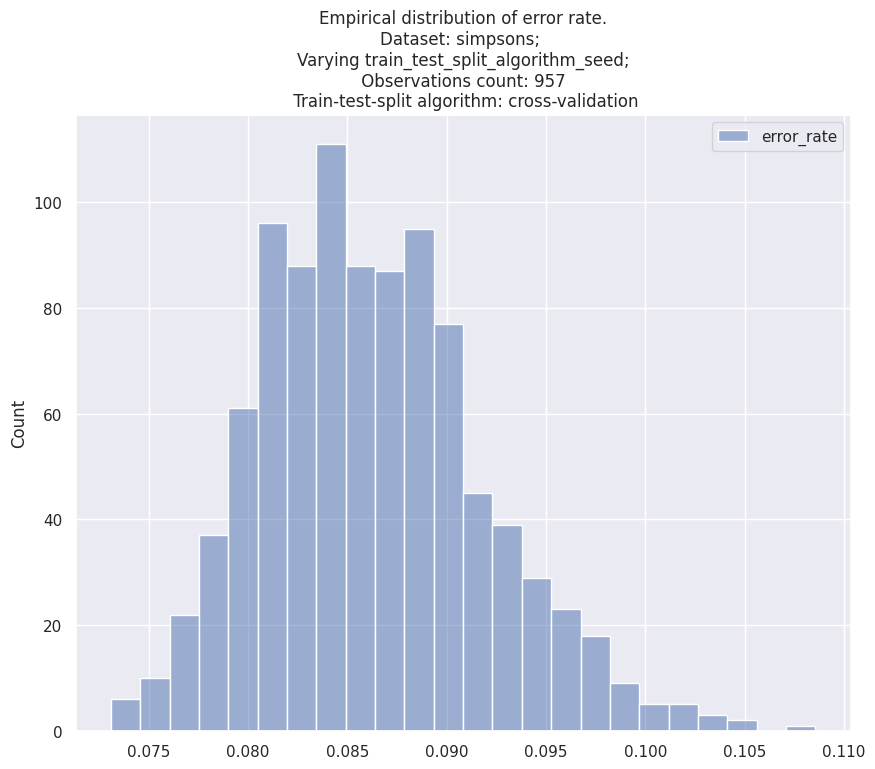

In [18]:
sns.histplot(metric_values, stat="count").set(
    title="Empirical distribution of error rate.\n"
          "Dataset: simpsons; \n"
          f"Varying {SEED_ATTR};\n "
          f"Observations count: {len(metric_values)} \n "
          f"Train-test-split algorithm: {list(opt_results.values())[0].config['train_test_split_algorithm']}"
)